# Praktikum 4 - Klasifikasi Citra Wajah

**Nama:** Agus  
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js11-klasifikasi-2/praktikum-4)

Kode utama di bawah mengikuti blok kode dan urutan modul. Penyesuaian terbatas pada lokasi dataset, kompatibilitas API, dan perbaikan error. Analisis tambahan ditempatkan setelah seluruh langkah modul.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
np.random.seed(42)
print("Kernel:", sys.executable)
# Pengaturan tampilan agar nama wajah dan label tidak bertumpuk.
plt.rcParams["figure.figsize"] = (12, 8)
plt.rcParams["figure.constrained_layout.use"] = True


Kernel: /Volumes/External/miniconda3/envs/ml-praktikum/bin/python


## Langkah 0 - Unduh Dataset

In [2]:
from sklearn.datasets import fetch_lfw_people
from sklearn.utils import Bunch
from pathlib import Path
local_data = Path('data/lfw_min60.npz')
if local_data.exists():
    with np.load(local_data, allow_pickle=False) as cached:
        faces = Bunch(**{name: cached[name] for name in cached.files})
else:
    faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


## Langkah 1 - Inspeksi Citra Wajah

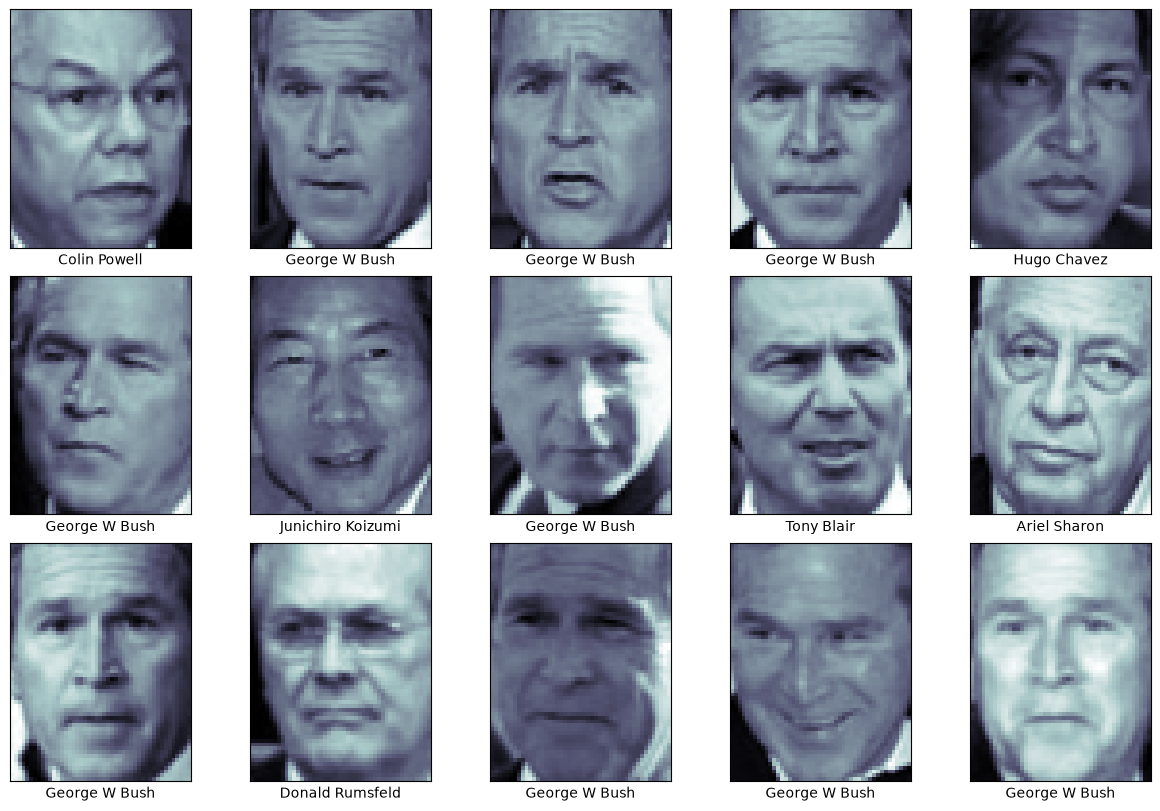

In [3]:
# contoh wajah yang digunakan
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])

## Langkah 2 - Pra Pengolahan Data

In [4]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline digunakan untuk melakukan proses secara bertahap dalam
# 1 eksekusi fungsi secara langsung
model = make_pipeline(pca, svc)

## Langkah 3 - Split Data

In [5]:
# pemisahan data training dan data testing

from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

## Langkah 4 - Pembuatan Model + Tunning

In [6]:
from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid, n_jobs=2)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

CPU times: user 120 ms, sys: 29.1 ms, total: 149 ms
Wall time: 4.54 s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


In [7]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

## Langkah 5 - Cek Hasil Prediksi

Text(0.5, 0.98, 'Predicted Names; Incorrect Labels in Red')

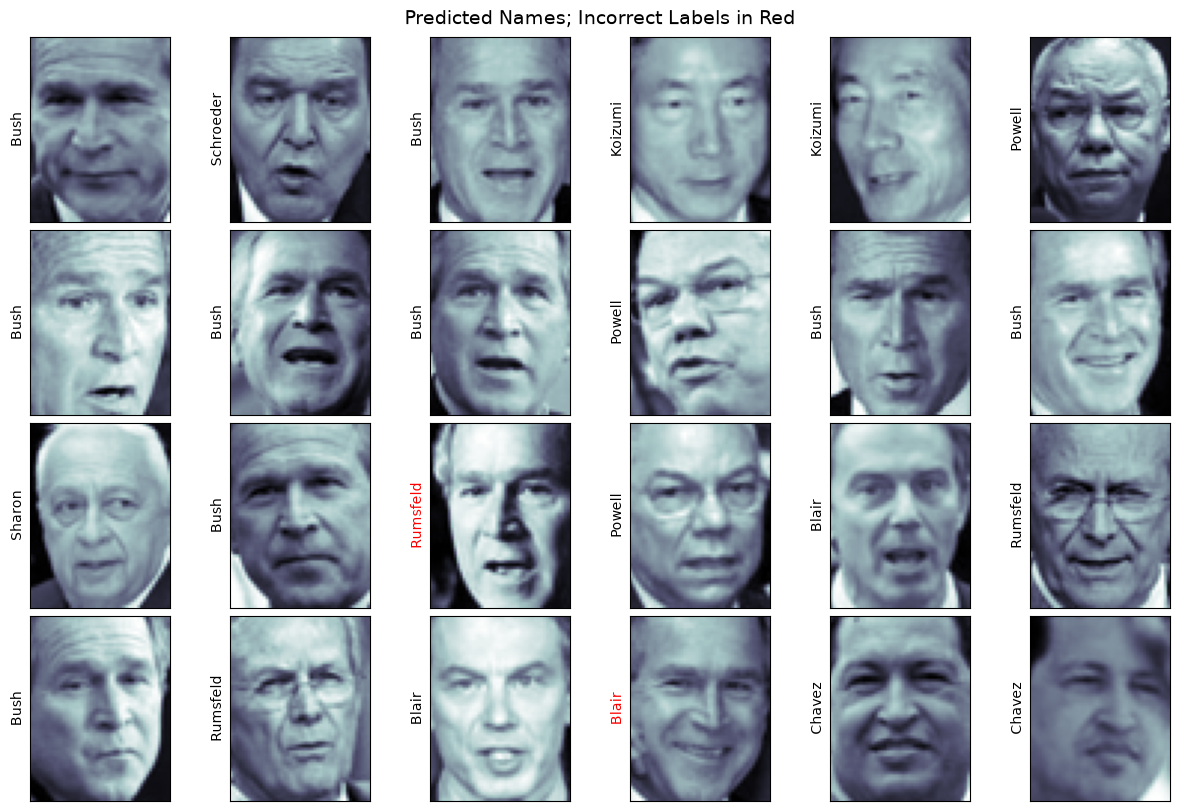

In [8]:
# hasil label pada data testing

fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

## Langkah 6 - Cek Performansi

In [9]:
from sklearn.metrics import classification_report
print(classification_report(ytest, yfit,
                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



Text(186.58203906249997, 0.5, 'predicted label')

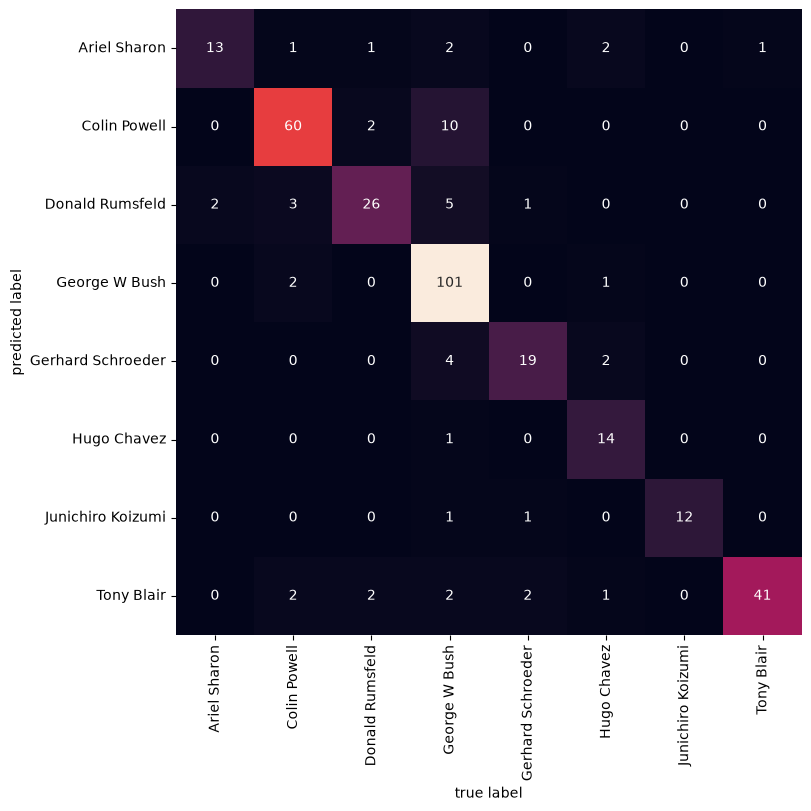

In [10]:
# bentuk confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')

## Evaluasi dan analisis tambahan

In [11]:
from sklearn.metrics import accuracy_score
from IPython.display import display, Markdown
display(Markdown(f'Akurasi CV **{grid.best_score_:.4f}** dan akurasi test '
                 f'**{accuracy_score(ytest, yfit):.4f}** pada **{len(ytest)}** citra. '
                 'PCA di-fit dalam pipeline setiap fold dan merangkum 2.914 piksel menjadi 150 komponen. '
                 'Perbedaan jumlah contoh antar identitas membuat macro F1 juga perlu diperhatikan.'))

Akurasi CV **0.8289** dan akurasi test **0.8487** pada **337** citra. PCA di-fit dalam pipeline setiap fold dan merangkum 2.914 piksel menjadi 150 komponen. Perbedaan jumlah contoh antar identitas membuat macro F1 juga perlu diperhatikan.